# From a data file to a result: cleaning and summarising a reactor temperature log

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 03 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/03_From_a_Data_File_to_a_Result.ipynb)

A batch reactor was heated for six hours, and a data logger recorded its temperature every five minutes. The operator sends you the log file and asks three questions: **What was the average temperature? When did it first exceed the 180 °C alarm limit? For how long did it stay above the limit?**

Real data files are rarely clean. This one uses semicolons between columns and commas as decimal points, as many European instruments do. One reading is missing, one is an error code, and the logger restarted halfway and wrote its header line again. Before calculating anything, a program must **read** the file, **understand** its format and **clean** it. That is the subject of this notebook: strings, lists, dictionaries, and reading and writing files.

**How to study:** predict each output before running a cell. The notebook uses plain Python, plus one plot made with Matplotlib.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 2, Collections and data |
| **Time** | about 45 min (about 75 min with the practice) |
| **Before this** | Notebooks 01–02. |
| **Essential** | All sections. |
| **Optional on a first reading** | Section 0 (how the example file is made). |
| **Next** | 04, Statistics, algorithms and complexity. |

**You have understood this notebook if you can, without looking back:**

1. Open a file with `with open(...)`, inspect its raw lines with `repr`, and describe its format.
2. Clean a line with `strip`, `split` and `replace`, and convert its fields to numbers.
3. Represent a missing value with `None` and keep it out of averages.
4. Use a dictionary to count problems or to group readings by hour.
5. Write a cleaned CSV file and a short report, then read the CSV back to check it.

**Not expected of you:** The pandas library. It does all of this in fewer lines, but first you should know what it does for you.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## 0. Setup: create the example file

In real work you would receive this file. Here a short program writes it, so that the notebook is self-contained. **You do not need to understand this cell yet.** Run it, and treat `reactor_log.csv` as a file someone sent you. (By the end of the notebook you will recognise every tool used in it.)

In [1]:
# The math module provides exp, sin and pi for the made-up temperature curve.
import math
# The first line of the file names the three columns.
header = "timestamp;temperature_C;status"
# Collect the file's lines in a list, starting with the header.
file_lines = [header]
# 73 readings: one every 5 minutes from 08:00 to 14:00.
for k in range(73):
    # Minutes since the start of the run.
    minutes = 5 * k
    # Clock time as "HH:MM", built with floor division and remainder.
    stamp = f"2026-03-14 {8 + minutes // 60:02d}:{minutes % 60:02d}"
    # A smooth heating curve with a small oscillation from the temperature controller.
    temperature = 150 + 35 * (1 - math.exp(-minutes / 60)) + 4 * math.sin(2 * math.pi * minutes / 45)
    # Write the value with one decimal and a decimal comma, as the logger does.
    value = f"{temperature:.1f}".replace(".", ",")
    # At 09:15 the reading is missing.
    if stamp.endswith("09:15"):
        # An empty field.
        value = ""
    # At 10:40 the sensor reported an error code.
    if stamp.endswith("10:40"):
        # The logger's error marker.
        value = "ERR"
    # Assemble the line with semicolons between the fields.
    line = f"{stamp};{value};RUN"
    # Some lines end with stray spaces, as happens in real exports.
    if k % 10 == 3:
        # Add two trailing spaces.
        line += "  "
    # Store the line.
    file_lines.append(line)
    # After 10:55 the logger restarted and wrote its header again.
    if stamp.endswith("10:55"):
        # The repeated header line.
        file_lines.append(header)
# Open the file for writing ("w") and close it automatically afterwards.
with open("reactor_log.csv", "w", encoding="utf-8") as out_file:
    # Join the lines with newline characters; end with an empty line, as some loggers do.
    out_file.write("\n".join(file_lines) + "\n\n")
# Confirm what was written.
print("wrote reactor_log.csv with", len(file_lines), "lines")

wrote reactor_log.csv with 75 lines


## 1. Look before you calculate

The first step with any data file is to **look at it**. `open(name)` connects to the file, and a `for` loop over the open file gives one line at a time as a string. The `with` block closes the file automatically when the block ends, even if something goes wrong.

`repr()` shows a string exactly as stored, including spaces and the invisible newline character `\n` at the end of each line.

In [2]:
# Open the file for reading (the default mode is "r").
with open("reactor_log.csv", encoding="utf-8") as log_file:
    # enumerate numbers the lines from 1 as we go.
    for line_number, raw_line in enumerate(log_file, start=1):
        # Show the first five lines exactly as stored.
        print(line_number, repr(raw_line))
        # Stop after line 5.
        if line_number == 5:
            # Leave the loop; the with block then closes the file.
            break

1 'timestamp;temperature_C;status\n'
2 '2026-03-14 08:00;150,0;RUN\n'
3 '2026-03-14 08:05;155,4;RUN\n'
4 '2026-03-14 08:10;159,3;RUN\n'
5 '2026-03-14 08:15;161,2;RUN  \n'


What we learn:

- the columns are separated by `;`;
- the decimal separator is a comma: `150,0` means 150.0;
- every line ends with `\n`, and line 5 has two stray spaces before it.

Python's `float("150,0")` would fail, so the commas must be replaced first.

## 2. Taking a line apart: string methods

A string has built-in **methods**, functions attached to it and called with a dot:

| Method | What it does | Example |
|---|---|---|
| `.strip()` | removes spaces and `\n` from both ends | `" 7 \n".strip()` → `"7"` |
| `.split(";")` | cuts at every `;` and returns a list of pieces | `"a;b;c".split(";")` → `["a", "b", "c"]` |
| `.replace(",", ".")` | replaces every `,` with `.` | `"150,0"` → `"150.0"` |
| `.startswith("x")` | `True` if the string begins with `"x"` | |

Strings can also be **sliced**: `text[11:16]` gives the characters from position 11 up to, but not including, 16. Positions count from 0.

In [3]:
# One raw line, exactly as it appears in the file (with trailing spaces).
sample = "2026-03-14 08:15;160,3;RUN  \n"
# Remove the newline and spaces at both ends.
clean = sample.strip()
# Cut the line at each semicolon: a list of three strings.
fields = clean.split(";")
# Show the pieces.
print(fields)
# The timestamp is the first field (index 0).
stamp = fields[0]
# Characters 11 to 15 hold the clock time "HH:MM".
print("clock time:", stamp[11:16])
# Characters 11 and 12 hold the hour; int() converts them to a number.
print("hour:", int(stamp[11:13]))
# Replace the decimal comma, then convert the text to a float.
print("temperature:", float(fields[1].replace(",", ".")))

['2026-03-14 08:15', '160,3', 'RUN']
clock time: 08:15
hour: 8
temperature: 160.3


## 3. Turning text into a number, or into "no value"

Two fields cannot be converted: the empty one and `ERR`. Converting them would stop the program with an error, and pretending they are zero would corrupt the average. The honest choice is to record **no value**, which Python writes as `None`.

We put the rule in a small function, so it can be tested on its own before it touches the data.

In [4]:
# Define a function that converts one temperature field.
def parse_temperature(text):
    # The docstring states the contract: what goes in, what comes out.
    """Return the temperature as a float, or None if the field is empty or an error code."""
    # Remove stray spaces first.
    text = text.strip()
    # An empty field or the logger's error code means "no reading".
    if text == "" or text == "ERR":
        # None is Python's value for "nothing here".
        return None
    # Otherwise replace the decimal comma and convert.
    return float(text.replace(",", "."))

# Test the function on every kind of field we expect to meet.
assert parse_temperature("160,3") == 160.3
# Spaces around the number are tolerated.
assert parse_temperature(" 99,5 ") == 99.5
# An empty field gives None.
assert parse_temperature("") is None
# The error code gives None.
assert parse_temperature("ERR") is None
# All checks passed if we reach this line.
print("parse_temperature passed 4 tests")

parse_temperature passed 4 tests


## 4. Read the whole file into lists

Now we read every line and keep two **parallel lists**: `times[i]` and `temperatures[i]` belong to the same reading. We also count the problems in a **dictionary**, a collection that maps each *key* (here, a kind of problem) to a *value* (how many times it occurred).

Lines are skipped if they are blank or if they repeat the header.

In [5]:
# Clock times of the readings, as "HH:MM" strings.
times = []
# Temperatures, as floats or None.
temperatures = []
# Counts of each kind of problem, starting at zero.
problems = {"blank line": 0, "repeated header": 0, "missing or error value": 0}
# Open the file for reading.
with open("reactor_log.csv", encoding="utf-8") as log_file:
    # Skip the very first line, the header (next() reads one line).
    next(log_file)
    # Read the remaining lines one by one.
    for raw_line in log_file:
        # Remove spaces and the newline.
        line = raw_line.strip()
        # An empty line carries no data ...
        if line == "":
            # ... so count it ...
            problems["blank line"] += 1
            # ... and move on to the next line.
            continue
        # A line that starts like the header is the logger's restart marker.
        if line.startswith("timestamp"):
            # Count it and skip it.
            problems["repeated header"] += 1
            # Move on to the next line.
            continue
        # Cut the line into its three fields; unpack them into three names.
        stamp, value_text, status = line.split(";")
        # Convert the temperature with our tested function.
        value = parse_temperature(value_text)
        # Count readings that have no usable value.
        if value is None:
            # One more missing or error value.
            problems["missing or error value"] += 1
        # Keep the clock time "HH:MM".
        times.append(stamp[11:16])
        # Keep the value, even if it is None, so the lists stay aligned in time.
        temperatures.append(value)
# How many readings, and which problems were found.
print("readings:", len(temperatures))
# The dictionary prints as {key: value, ...}.
print("problems:", problems)
# The two lists must have the same length.
assert len(times) == len(temperatures) == 73

readings: 73
problems: {'blank line': 1, 'repeated header': 1, 'missing or error value': 2}


## 5. Summarise the valid readings

A **list comprehension** builds a new list from an old one in a single line. `[t for t in temperatures if t is not None]` reads as: "every `t` from `temperatures`, but only if `t` is not `None`". With the valid values in hand, the built-in functions `min`, `max`, `sum` and `len` do the rest.

In [6]:
# Keep only the readings that have a value.
valid = [t for t in temperatures if t is not None]
# Mean = sum / count.
mean_temperature = sum(valid) / len(valid)
# Report the summary with one decimal.
print(f"valid readings: {len(valid)} of {len(temperatures)}")
# Lowest, highest and average temperature.
print(f"min = {min(valid):.1f} °C, max = {max(valid):.1f} °C, mean = {mean_temperature:.1f} °C")
# Check the mean the long way: an explicit loop must give the same answer.
running_total = 0.0
# Add up every valid value.
for t in valid:
    # Accumulate.
    running_total += t
# Compare the two calculations.
assert math.isclose(running_total / len(valid), mean_temperature)

valid readings: 71 of 73
min = 150.0 °C, max = 188.8 °C, mean = 179.1 °C


## 6. Answer the operator's questions: the 180 °C alarm limit

*When did the temperature first exceed 180 °C?* We walk through the readings with `enumerate`, which supplies each position together with its value, and stop at the first one above the limit.

*How long did it stay above?* The temperature oscillates, so it crosses the limit several times. We find the **longest unbroken run** of readings above the limit. Missing values break a run, because we cannot know what happened then.

In [7]:
# The alarm limit, in °C.
limit = 180.0
# No crossing found yet.
first_index = None
# Visit each reading with its position.
for i, t in enumerate(temperatures):
    # A valid reading above the limit?
    if t is not None and t > limit:
        # Remember its position ...
        first_index = i
        # ... and stop at the first one.
        break
# Report the time of the first exceedance.
print("first reading above 180 °C at", times[first_index], f"({temperatures[first_index]} °C)")
# Number of readings above the limit in total.
n_above = sum(1 for t in valid if t > limit)
# Report it.
print("readings above the limit:", n_above, "of", len(valid))

# Length of the current run of readings above the limit.
current_run = 0
# Longest run seen so far, and the position where it ended.
longest_run, longest_end = 0, None
# Visit every reading in time order.
for i, t in enumerate(temperatures):
    # Above the limit: the current run grows by one.
    if t is not None and t > limit:
        # One more reading in this run.
        current_run += 1
        # Is this the longest run so far?
        if current_run > longest_run:
            # Remember its length and where it ends.
            longest_run, longest_end = current_run, i
    # Below the limit, or no value: the run is broken.
    else:
        # Start counting again from zero.
        current_run = 0
# Start of the longest run: count back from its end.
longest_start = longest_end - longest_run + 1
# Readings are 5 min apart, so a run of n readings spans (n − 1) × 5 min.
print(f"longest run above the limit: {longest_run} readings, "
      f"{times[longest_start]}–{times[longest_end]} ({(longest_run - 1) * 5} min)")

first reading above 180 °C at 09:35 (180.4 °C)
readings above the limit: 47 of 71
longest run above the limit: 38 readings, 10:55–14:00 (185 min)


## 7. Group by hour with a dictionary

The operator also wants the average temperature in each hour. A dictionary is a natural tool: the **key** is the hour and the **value** is a list of that hour's readings. `setdefault(key, [])` returns the list stored for `key`, creating an empty list the first time a key is seen.

In [8]:
# Empty dictionary: hour → list of valid readings in that hour.
by_hour = {}
# zip walks through the two parallel lists together.
for clock, t in zip(times, temperatures):
    # Readings without a value are left out of the averages.
    if t is None:
        # Skip to the next reading.
        continue
    # The hour is the first two characters of "HH:MM".
    hour = int(clock[:2])
    # Append this reading to its hour's list (creating the list if needed).
    by_hour.setdefault(hour, []).append(t)
# Table header.
print("hour  readings  mean (°C)")
# Visit the hours in increasing order.
for hour in sorted(by_hour):
    # The readings of this hour.
    readings = by_hour[hour]
    # One table row.
    print(f"{hour:02d}:00  {len(readings):>8}  {sum(readings) / len(readings):9.1f}")
# Every valid reading must appear in exactly one hour.
assert sum(len(r) for r in by_hour.values()) == len(valid)

hour  readings  mean (°C)
08:00        12      162.5
09:00        11      177.3
10:00        11      181.0
11:00        12      184.4
12:00        12      184.9
13:00        12      184.0
14:00         1      184.9


## 8. Look at the data

A plot shows in a second what the tables took several cells to establish. Matplotlib's `plt.plot(x, y)` draws a line through the points given by two lists of equal length. We plot only the valid readings, so the gaps at 09:15 and 10:40 stay visible as missing points.

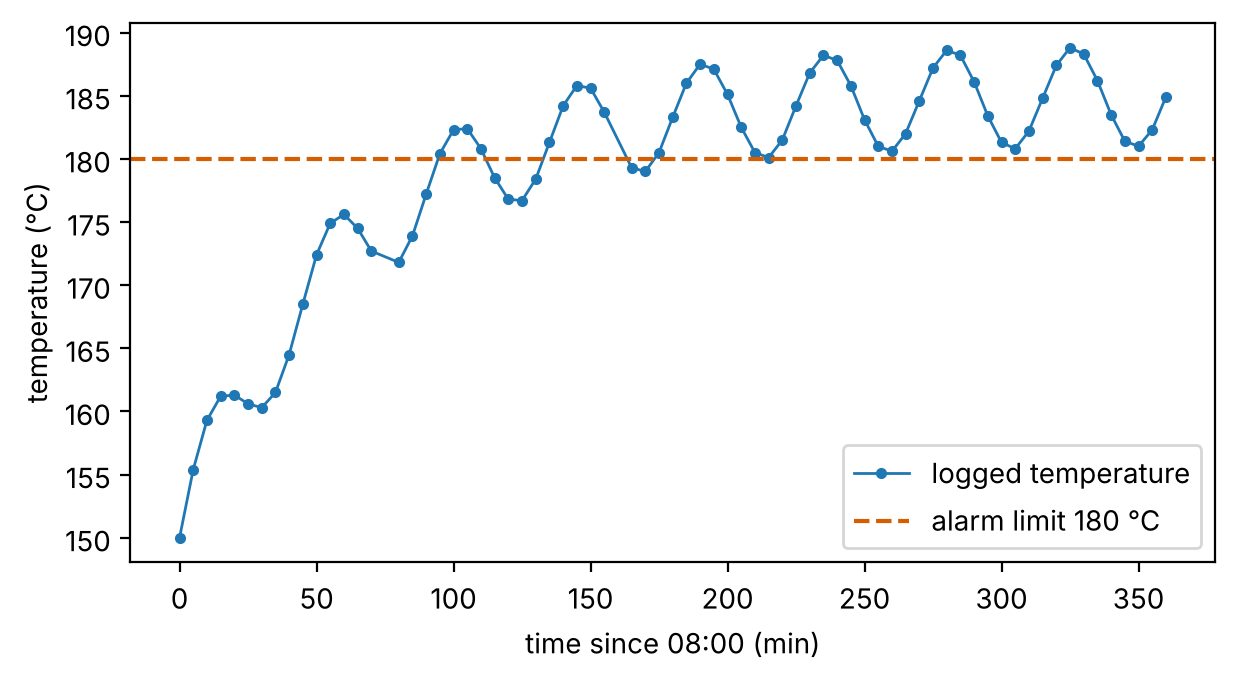

In [9]:
# Load Matplotlib's plotting interface.
import matplotlib.pyplot as plt
# Minutes since 08:00 for each reading: position × 5.
minutes_all = [5 * i for i in range(len(temperatures))]
# Minutes of the valid readings only.
minutes_valid = [m for m, t in zip(minutes_all, temperatures) if t is not None]
# Create a figure 7 inches wide and 3.5 inches tall.
plt.figure(figsize=(7, 3.5))
# Draw the valid readings as dots joined by a thin line.
plt.plot(minutes_valid, valid, marker="o", markersize=3, linewidth=1, label="logged temperature")
# Draw the alarm limit as a dashed horizontal line.
plt.axhline(limit, color="#D55E00", linestyle="--", label="alarm limit 180 °C")
# Label the axes, with units.
plt.xlabel("time since 08:00 (min)")
# The y-axis label.
plt.ylabel("temperature (°C)")
# Legend in the lower right, where the curve leaves space.
plt.legend(loc="lower right")
# Display the figure.
plt.show()

## 9. Write the results to new files

Cleaned data should be saved in a format that any program can read: commas between columns, points as decimal separators and an empty field for a missing value. Python's `csv` module writes and reads such files correctly, including fields that themselves contain commas. A short text report records the answers to the operator's questions.

Opening a file with `"w"` **creates or overwrites** it. The original log stays unchanged; never overwrite your raw data.

In [10]:
# The csv module reads and writes comma-separated files.
import csv
# Open a new file for writing; newline="" lets the csv module control line endings.
with open("reactor_log_clean.csv", "w", newline="", encoding="utf-8") as clean_file:
    # A writer object turns lists into correctly formatted CSV lines.
    writer = csv.writer(clean_file)
    # Write the column names.
    writer.writerow(["time", "temperature_C"])
    # One row per reading.
    for clock, t in zip(times, temperatures):
        # Missing values become empty fields, never zeros.
        writer.writerow([clock, "" if t is None else t])
# Build the report as a list of lines.
report_lines = [
    "Reactor temperature log, 2026-03-14, 08:00-14:00",
    f"valid readings: {len(valid)} of {len(temperatures)}; problems: {problems}",
    f"mean temperature: {mean_temperature:.1f} C (min {min(valid):.1f}, max {max(valid):.1f})",
    f"first reading above {limit:.0f} C: {times[first_index]}",
    f"longest run above the limit: {times[longest_start]}-{times[longest_end]} ({(longest_run - 1) * 5} min)",
]
# Write the report, one line per item.
with open("reactor_report.txt", "w", encoding="utf-8") as report_file:
    # Join with newlines and end with one.
    report_file.write("\n".join(report_lines) + "\n")
# Show the report on screen as well.
print("\n".join(report_lines))

Reactor temperature log, 2026-03-14, 08:00-14:00
valid readings: 71 of 73; problems: {'blank line': 1, 'repeated header': 1, 'missing or error value': 2}
mean temperature: 179.1 C (min 150.0, max 188.8)
first reading above 180 C: 09:35
longest run above the limit: 10:55-14:00 (185 min)


**Check by reading the file back.** A file you wrote is only useful if it can be read correctly. `csv.reader` gives each line as a list of strings, already split at the commas.

In [11]:
# Read the cleaned file back.
with open("reactor_log_clean.csv", newline="", encoding="utf-8") as clean_file:
    # A reader object yields one list of strings per line.
    rows = list(csv.reader(clean_file))
# The first row holds the column names.
print("header:", rows[0])
# The next three data rows.
print("first rows:", rows[1:4])
# Convert back, keeping empty fields as None.
values_back = [None if r[1] == "" else float(r[1]) for r in rows[1:]]
# The round trip must reproduce exactly what we wrote.
assert values_back == temperatures
# Report success.
print("round trip OK:", len(values_back), "readings")

header: ['time', 'temperature_C']
first rows: [['08:00', '150.0'], ['08:05', '155.4'], ['08:10', '159.3']]
round trip OK: 73 readings


## 10. Practice

Try each question in the empty cell first, then compare with the worked answers.

1. How many readings fall in the 12:00 hour, and what is their mean? (Use `by_hour`.)
2. Write a function `is_header(line)` that returns `True` for a header line, and test it with two `assert` statements.
3. What would the mean temperature be if the missing and error values had wrongly been counted as 0 °C? How large is the error?
4. Find the **last** reading above 180 °C. Hint: loop over `range(len(temperatures) - 1, -1, -1)`, which counts backwards.

In [12]:
# Your work for the practice questions goes here.

**Worked answers.** Run the cell after you have tried the questions.

In [13]:
# Q1: the readings of the 12:00 hour.
noon = by_hour[12]
# Count and mean.
print(f"Q1: {len(noon)} readings, mean {sum(noon) / len(noon):.1f} °C")
# Q2: a header line starts with the first column name.
def is_header(line):
    # strip() first, so leading spaces do not hide the header.
    return line.strip().startswith("timestamp")

# A header line is recognised ...
assert is_header("timestamp;temperature_C;status\n")
# ... and a data line is not.
assert not is_header("2026-03-14 08:15;160,3;RUN")
# Report that the tests passed.
print("Q2: is_header passed 2 tests")
# Q3: treating the two missing values as zero pulls the mean down.
wrong_mean = sum(valid) / len(temperatures)
# Report both means and the error.
print(f"Q3: wrong mean {wrong_mean:.1f} °C vs correct {mean_temperature:.1f} °C (error {mean_temperature - wrong_mean:.1f} °C)")
# Q4: walk backwards from the last reading.
for i in range(len(temperatures) - 1, -1, -1):
    # The first valid reading above the limit, seen from the end.
    if temperatures[i] is not None and temperatures[i] > limit:
        # Report it ...
        print("Q4: last reading above 180 °C at", times[i])
        # ... and stop.
        break

Q1: 12 readings, mean 184.9 °C
Q2: is_header passed 2 tests
Q3: wrong mean 174.2 °C vs correct 179.1 °C (error 4.9 °C)
Q4: last reading above 180 °C at 14:00


## What to take away

- **Look at a data file before trusting it.** `repr()` reveals separators, decimal commas, spaces and line endings.
- String methods (`strip`, `split`, `replace`, `startswith`) and slicing turn text into fields.
- Represent a missing value as `None`, never as zero, and keep it out of averages.
- Lists hold sequences; dictionaries map keys to values; list comprehensions filter and transform in one line.
- `with open(...)` reads and writes files safely; the `csv` module handles the format. Read your output back to check it.

You can now get data *into* a program. Notebook 04 asks what happens *inside* it: how many operations a statistic costs, and why the choice of algorithm matters as data grow.